# Horizon Forecaster — daily example

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Lifesight-Software-Pvt-Ltd/horizon/blob/main/examples/daily_website_traffic.ipynb)

A complete daily run: evaluate five forecasting models on one series, combine them,
forecast forward, and export the results.

**What this notebook shows**

- the three-way train / validation / test split, and why the two MAPEs it reports are not interchangeable
- several combination rules built side by side, and how to tell whether any of them beat the best single model
- supplying future values for the drivers you *do* know, while the library generates the ones you do not
- the chart and CSV outputs

There is a weekly counterpart in this folder; the API is identical, only the frequency defaults differ.

---

### Dataset

**Personal Ecommerce Website Ad cost & viewer count**, by Kaggle user `michealknight`, licensed **Apache 2.0**.
Source: https://www.kaggle.com/datasets/michealknight/personal-ecommerce-website-ad-cost-and-viewer-count

The CSV in `examples/data/` is the file exactly as downloaded — no columns removed, no values changed.
Every bit of preparation happens in this notebook, in the open, so you can disagree with any of it.
1096 daily rows, 2022-01-01 to 2024-12-31.

**This is simulated data**, as the dataset's own Kaggle subtitle says ("Simulated Daily Web Analytics"). That suits this notebook: its job is to show how the library works end to end on an external dataset, not to make claims about any real website's traffic.

## Before you run

**This notebook fits real models.** Prophet and PyMC compile on first use, and the fast path below
takes a few minutes on a free Colab CPU. The full five-model run takes considerably longer —
Bayesian PyMC draws a full MCMC sample per grid candidate. Both cells are provided; start with the fast one.

**On Colab specifically:** the default runtime is Python 3.13, and `neuralprophet` pins `numpy<2`,
which publishes no 3.13 wheel — so pip compiles numpy from source and the install takes several extra minutes.
To skip that, set **Runtime → Change runtime type → Runtime version → 2026.07** (Python 3.12) before running.
See [`docs/installation.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/installation.md) for the full explanation.

In [ ]:
# Installing from the repository. Once the package is on PyPI this becomes:
#     %pip install -q horizon_forecaster
%pip install -q "git+https://github.com/Lifesight-Software-Pvt-Ltd/horizon.git"

In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from horizon_forecaster import HorizonForecaster, __version__
from horizon_forecaster.exporters import export_forecast
from horizon_forecaster.plotting import (
    plot_evaluation,
    plot_evaluation_per_model,
    plot_forecast,
    plot_model_comparison,
)

print('horizon_forecaster', __version__)

# Warnings are part of the library's output -- it warns about auto-generated
# drivers, over-long horizons and implausible forecasts. Keep them visible.
warnings.simplefilter('always', UserWarning)

horizon_forecaster 1.0.0


## 1. The data

Loaded straight from the repository, so this runs in Colab with nothing to download by hand.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/Lifesight-Software-Pvt-Ltd/horizon/main/examples/data/final_website_stats.csv"

raw = pd.read_csv(DATA_URL)
print(raw.shape)
raw.head()

(1096, 7)


,Unnamed: 0,timestamp,page_views,ad_spend,is_weekend,day_of_week,is_holiday
0,0,2022-01-01,1165.962767,194.901425,True,Saturday,True
1,1,2022-01-02,1191.485835,175.852071,True,Sunday,False
2,2,2022-01-03,1266.928269,269.430656,False,Monday,False
3,3,2022-01-04,1364.193858,295.690896,False,Tuesday,False
4,4,2022-01-05,1013.282520,242.975399,False,Wednesday,False


### Preparing it

Four changes, and the reason for each:

| Change | Why |
|---|---|
| drop the unnamed first column | a pandas index saved into the CSV, not data |
| drop `day_of_week` | a string, which the library will not accept; it is also redundant — `is_weekend` carries the signal, and Prophet and NeuralProphet model weekly seasonality natively |
| `is_weekend`, `is_holiday` to `int` | booleans are not numeric for our purposes; 0/1 also lets the library auto-detect them as event flags |
| rename `timestamp` to `date` | cosmetic |

Note what is *not* here: no filling, no imputing, no dropping of rows. The library requires complete
data and raises `InvalidConfigError` on a single missing cell rather than guessing — so the check below
is worth doing before you construct anything.

In [4]:
df = (
    raw.drop(columns=['Unnamed: 0', 'day_of_week'])
       .rename(columns={'timestamp': 'date'})
       .assign(
           date=lambda d: pd.to_datetime(d['date']),
           is_weekend=lambda d: d['is_weekend'].astype(int),
           is_holiday=lambda d: d['is_holiday'].astype(int),
       )
       .sort_values('date')
       .reset_index(drop=True)
)

# The three things the library cares about before it will take the frame.
print('rows             :', len(df))
print('missing cells    :', int(df.isna().sum().sum()))
print('duplicate dates  :', int(df['date'].duplicated().sum()))
print('day gaps present :', sorted(df['date'].diff().dt.days.dropna().unique()))
df.head()

rows             : 1096
missing cells    : 0
duplicate dates  : 0
day gaps present : [1.0]


,date,page_views,ad_spend,is_weekend,is_holiday
0,2022-01-01,1165.962767,194.901425,1,1
1,2022-01-02,1191.485835,175.852071,1,0
2,2022-01-03,1266.928269,269.430656,0,0
3,2022-01-04,1364.193858,295.690896,0,0
4,2022-01-05,1013.282520,242.975399,0,0


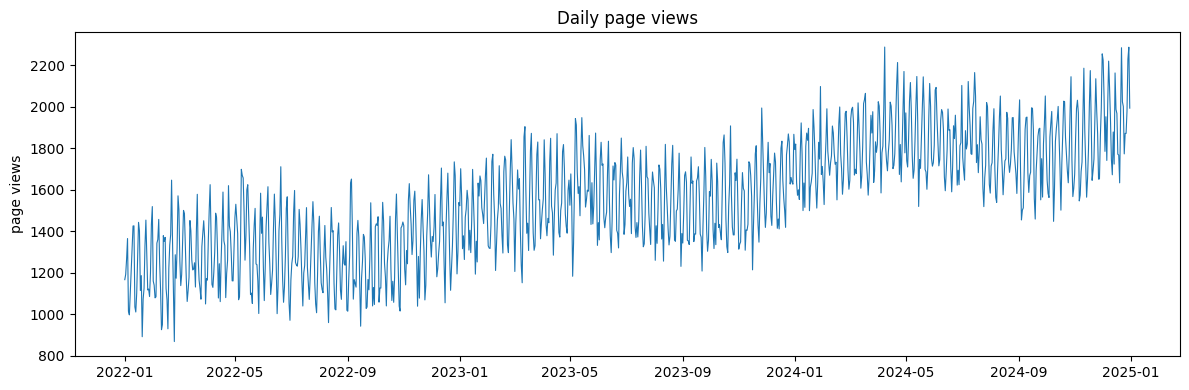

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df['date'], df['page_views'], linewidth=0.8)
ax.set_title('Daily page views')
ax.set_ylabel('page views')
fig.tight_layout()
plt.show()

Three years of daily data with a clear upward trend and visible weekly structure.
That is the kind of series this library is built for.

A note on the drivers, since an example should not oversell them: `ad_spend` correlates with
`page_views` at **-0.003** on the same day, and stays below 0.25 at every lag from 0 to 7 days (it peaks at about 0.24, three to five days later). In this dataset it carries little signal.
It is kept because it exercises the exogenous path end to end — standardisation in SARIMAX, the
regression term in Bayesian PyMC — not because it helps the forecast. `is_weekend` and `is_holiday`
are the drivers that actually matter here, and both are *known in advance*, which §5 makes use of.

## 2. Constructing the forecaster

Every argument below is optional except the first four. The values shown are the defaults,
written out so you can see what you would otherwise be accepting.

In [6]:
TARGET   = 'page_views'
DRIVERS  = ['ad_spend', 'is_weekend', 'is_holiday']

# Fast path: three models, each still fully grid-searched, so the real selection
# machinery runs. Set FAST = False for all five -- see the note at the top about runtime.
FAST = True
MODELS = ['prophet', 'catboost', 'sarimax'] if FAST else None   # None = every registered model

forecaster = HorizonForecaster(
    df,
    date_column='date',
    target_column=TARGET,
    frequency='daily',
    independent_columns=DRIVERS,
    validation_size=None,      # None -> 84 periods for daily. Every DECISION is scored here.
    test_size=None,            # None -> 28 periods for daily. REPORTED, never selected on.
    models=MODELS,
    mape_threshold=40.0,       # degenerate-fit filter on the validation MAPE; None admits everything
    ensemble_method=None,      # None -> build all three rules: trimmed, inverse_mape, equal
    future_exog_strategy='carry_forward',
    event_columns=['is_weekend', 'is_holiday'],   # 0/1 flags; declaring them beats auto-detection
)

print('models      :', MODELS or 'all registered')
print('ensembles   :', forecaster.ensemble_methods)

models      : ['prophet', 'catboost', 'sarimax']
ensembles   : ['trimmed', 'inverse_mape', 'equal']


## 3. Evaluate

`evaluate()` splits the series chronologically into **train / validation / test**, grid-searches each
model's hyperparameters on the validation window, refits the winner on train + validation, and scores
it once on the test window — which no selection path is ever allowed to read.

That is why every result carries two MAPEs, and why they mean different things:

| field | window | meaning |
|---|---|---|
| `validation_mape` | validation | the score every decision was made on. Optimistic by construction — candidates were chosen to minimise it. |
| `mape` | test | the score reported. The honest out-of-sample number. |

A large gap between them means the grid found a candidate that suited the validation window
specifically rather than the series generally.

In [7]:
%%time
results = forecaster.evaluate()

CPU times: user 1min 16s, sys: 8.16 s, total: 1min 24s
Wall time: 46.2 s


In [8]:
summary = pd.DataFrame([
    {
        'model': name,
        'test MAPE %': round(r.mape.value, 2),
        'validation MAPE %': round(r.validation_mape.value, 2),
        'train': r.n_train,
        'validation': r.n_validation,
        'test': r.n_test,
    }
    for name, r in results.items()
]).sort_values('test MAPE %').reset_index(drop=True)

summary

,model,test MAPE %,validation MAPE %,train,validation,test
0,sarimax,4.02,3.75,1012,56,28
1,prophet,4.07,3.73,1012,56,28
2,catboost,4.33,4.49,1012,56,28


In [9]:
# Models that failed to fit or predict at all are recorded separately from models
# that fitted but were not admitted to a combination. The two are never conflated.
print('failed to fit :', dict(forecaster.evaluate_errors) or 'none')

failed to fit : none


### The ensembles

All three rules were built from the same fitted models — combination is arithmetic over predictions
already in memory, so asking for every rule costs essentially nothing beyond the first.

`weights` is `None` for the trimmed rule, which has no weights at all. That is not an oversight:
an empty dict already means "no member survived", so a weightless rule has to report something else.

In [10]:
rows = []
for method, ens in forecaster.evaluate_ensemble.items():
    rows.append({
        'method': method,
        'rule applied': ens.rule_applied,
        'degraded': ens.degraded,
        'members': len(ens.members),
        'MAPE %': round(ens.mape.value, 2) if ens.mape is not None else None,
        'weights': ens.weights,
        'rejected': list(ens.rejected_models) or None,
    })

pd.DataFrame(rows)

,method,rule applied,degraded,members,MAPE %,weights,rejected
0,trimmed,trimmed,False,3,4.07,None,None
1,inverse_mape,inverse_mape,False,3,4.03,"{'prophet': 0.35346511154026894, 'catboost': 0...",None
2,equal,equal,False,3,4.04,"{'prophet': 0.3333333333333333, 'catboost': 0....",None


**Compare those against the per-model table above before trusting any of them.**

A combined forecast is *not* guaranteed to beat the best single model. With static weights it can be
dragged off on exactly the periods where a weaker member is wrong; trimming is considerably more robust
to that, since it discards the offending member on the periods where it offends, but it is still not a
guarantee. This is a real property of combination, not a defect — which is why the library scores every
ensemble against actuals and the exporter writes both a combined and a best-single-model CSV.

## 4. Charts

`plot_evaluation` returns **one chart per combination rule**, keyed by method — always a dict, even for
a single rule. Each chart carries the same models and actuals against a different combination, so the
rules are comparable against the truth rather than only against each other.

charts returned: ['trimmed', 'inverse_mape', 'equal']


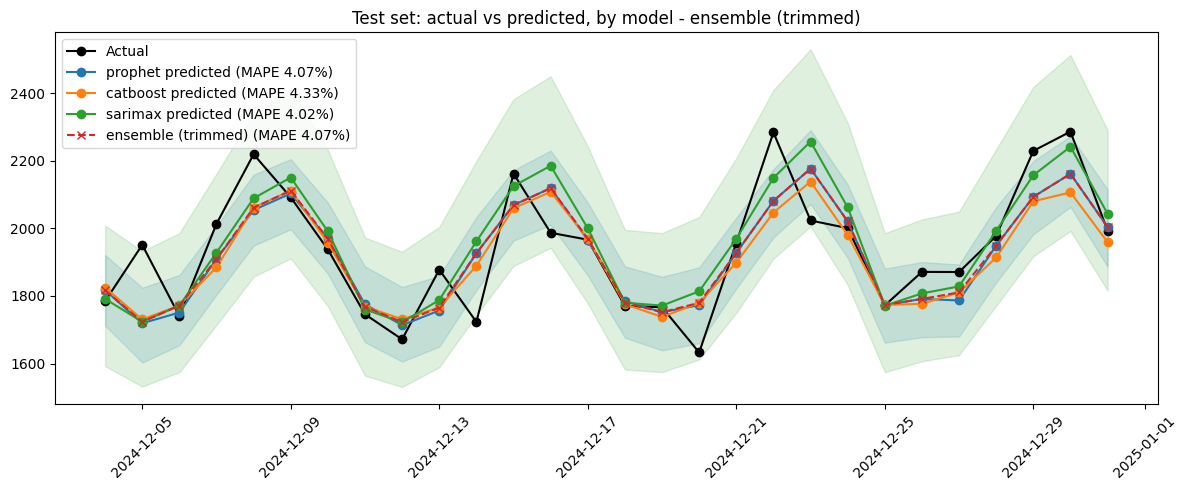

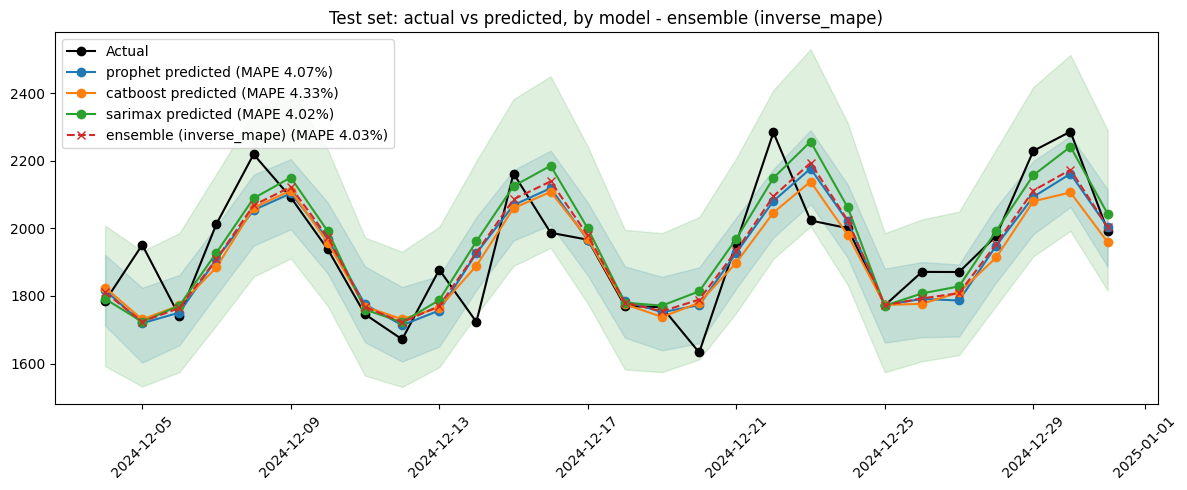

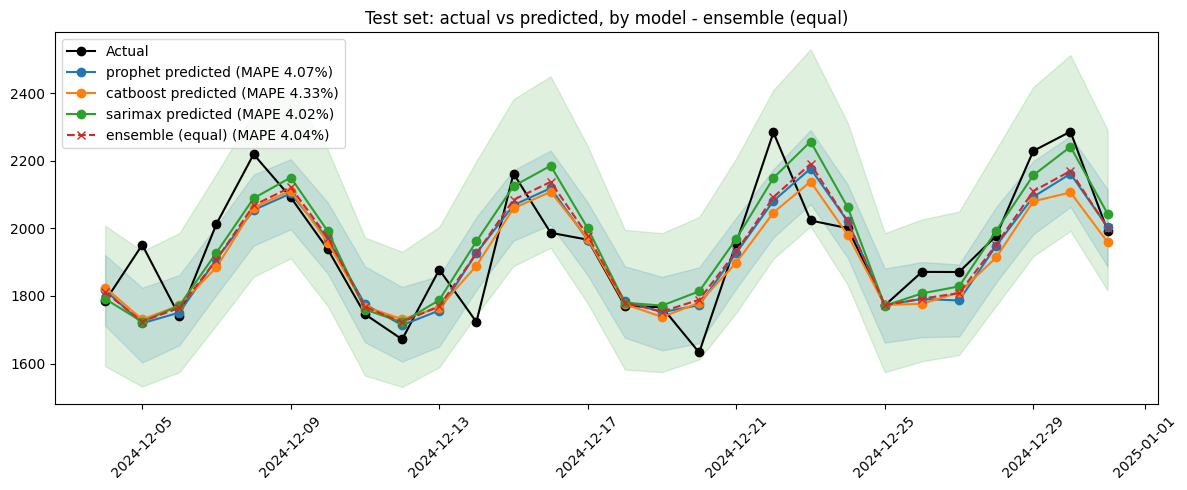

In [11]:
axes = plot_evaluation(results, forecaster.evaluate_ensemble)
print('charts returned:', list(axes))
plt.show()

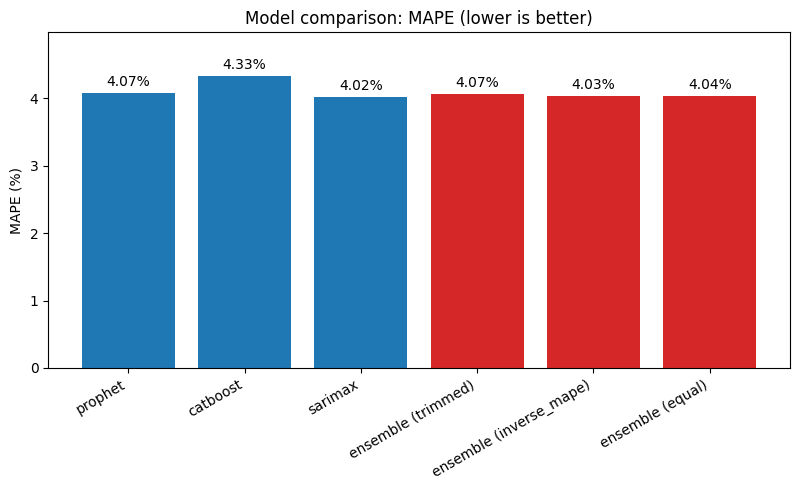

In [12]:
# Every rule on one axes -- comparing rules head to head is what a bar chart is for.
# These bars are TEST-window MAPEs, not the validation scores the models were selected on.
plot_model_comparison(results, forecaster.evaluate_ensemble)
plt.show()

figures: ['prophet', 'catboost', 'sarimax', 'ensemble_trimmed', 'ensemble_inverse_mape', 'ensemble_equal']


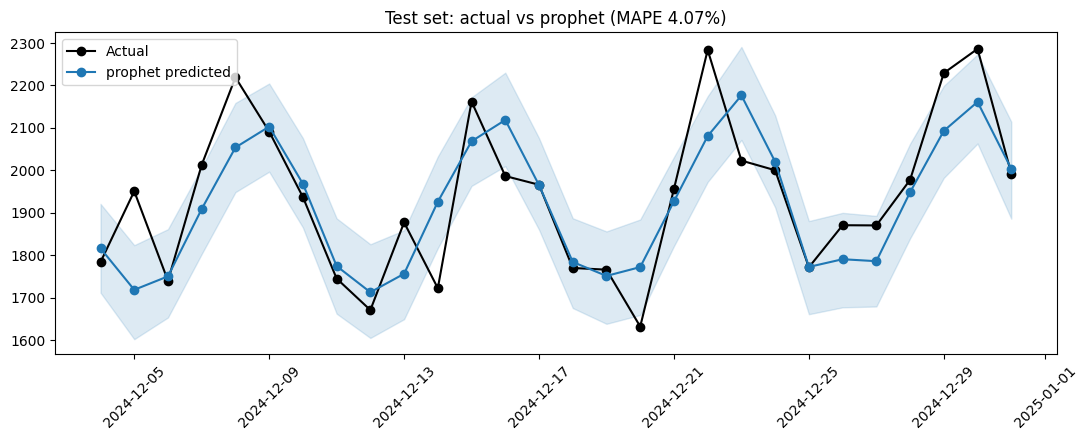

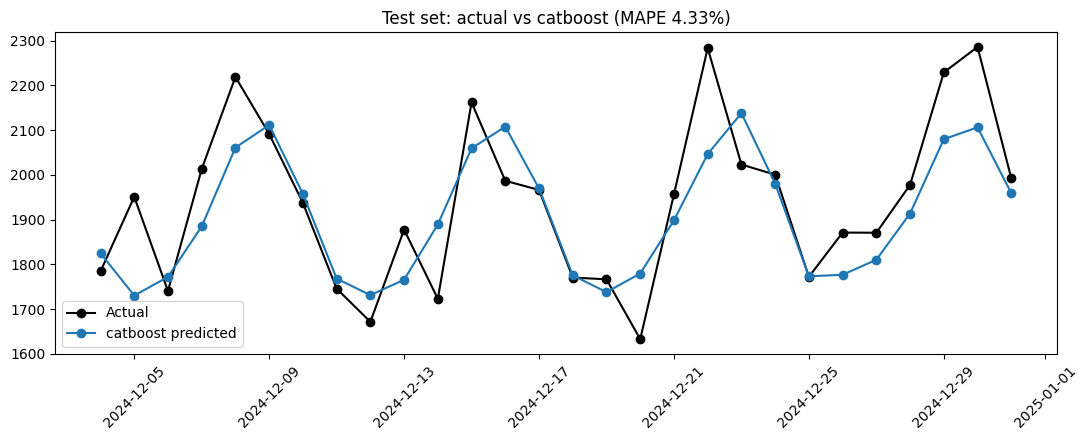

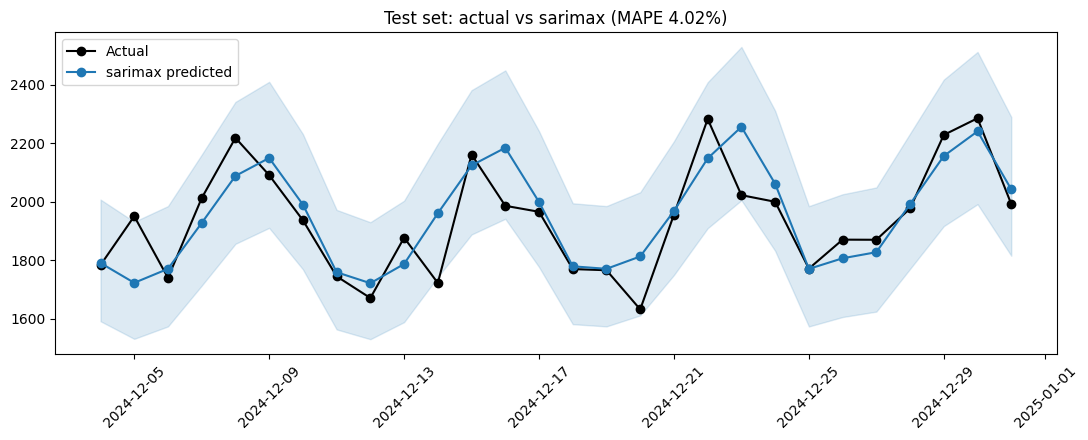

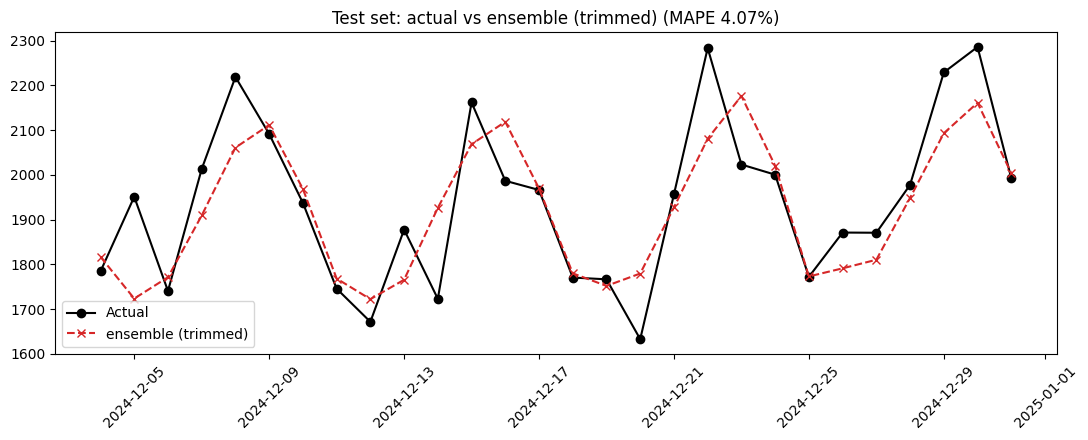

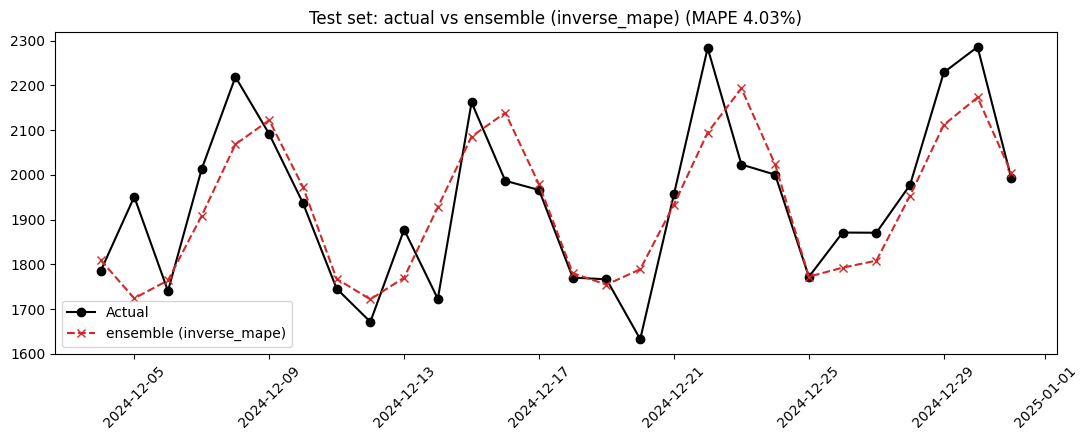

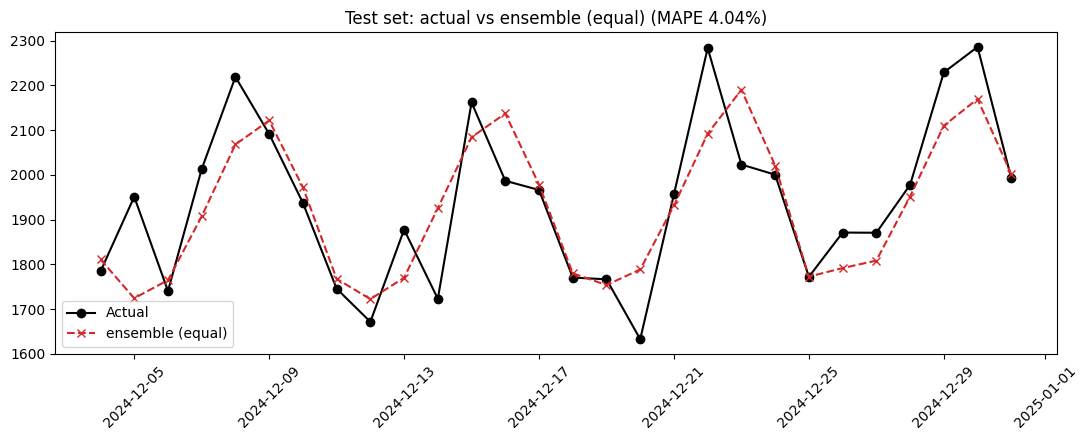

In [13]:
# One full-size figure per model, plus one per rule that formed. Easier to read than
# the overlay once several models agree and their lines sit on top of each other.
figures = plot_evaluation_per_model(results, forecaster.evaluate_ensemble)
print('figures:', list(figures))
plt.show()

## 5. Forecasting forward

This is where the driver columns earn their place, and where the distinction between drivers you know
and drivers you do not becomes concrete.

- `is_weekend` and `is_holiday` are **calendar facts**. We can compute them for any future date, so we supply them.
- `ad_spend` is **not knowable**. We leave it out, and the library generates it with the configured
  `carry_forward` strategy — and warns, loudly, that it has done so.

Supplying some columns and leaving others out is **partial fill**: a supplied column is used as-is and
only the missing ones are generated. The table also carries a `date` column, which the library checks against
the forecast dates, so a table that starts on the wrong day or skips one is refused rather than misapplied.
Partial fill matches the real case — you know next month's promotional
calendar, but not what spend will actually land.

In [14]:
HORIZON = 30

future_dates = pd.date_range(
    start=df['date'].max() + pd.Timedelta(days=1), periods=HORIZON, freq='D'
)

# Known-in-advance calendar flags. is_holiday is left at 0 here; in a real run you would
# mark your actual holiday dates, which is exactly the point of being able to supply it.
future_drivers = pd.DataFrame({
    'date': future_dates,   # optional, but checked against the forecast dates when present
    'is_weekend': (future_dates.dayofweek >= 5).astype(int),
    'is_holiday': 0,
})

print(f"supplying {list(future_drivers.columns.drop('date'))} for {HORIZON} periods; ad_spend will be generated")
future_drivers.head()

supplying ['is_weekend', 'is_holiday'] for 30 periods; ad_spend will be generated


,date,is_weekend,is_holiday
0,2025-01-01,0,0
1,2025-01-02,0,0
2,2025-01-03,0,0
3,2025-01-04,1,0
4,2025-01-05,1,0


In [15]:
%%time
forecasts = forecaster.forecast(horizon=HORIZON, future_independent_data=future_drivers)

<timed exec>:1: UserWarning: future values for ['ad_spend'] were auto-generated for all 30 periods via the 'carry_forward' strategy (no values were supplied for them). The forecast is only as reliable as those assumed inputs -- for an exogenous-variable-driven model this can dominate the result. Supply real planned values if you have them (you can supply just some columns; the rest are filled), inspect what was assumed via forecaster.future_exog_used, and treat this output as a scenario rather than a prediction.


CPU times: user 7.7 s, sys: 258 ms, total: 7.96 s
Wall time: 4.35 s


Note the warning above: it names the columns that were invented and the strategy used, and says to
treat the output as a scenario rather than a prediction. That is deliberate — an exogenous-driven
forecast can be dominated by assumed inputs, and silently inventing them would hide that.

You can always inspect exactly what was assumed:

In [16]:
# Supplied columns and generated columns together, with the dates they apply to.
forecaster.future_exog_used.head()

,ds,ad_spend,is_weekend,is_holiday
0,2025-01-01,247.578503,0.0,0.0
1,2025-01-02,247.578503,0.0,0.0
2,2025-01-03,247.578503,0.0,0.0
3,2025-01-04,247.578503,1.0,0.0
4,2025-01-05,247.578503,1.0,0.0


charts returned: ['trimmed', 'inverse_mape', 'equal']


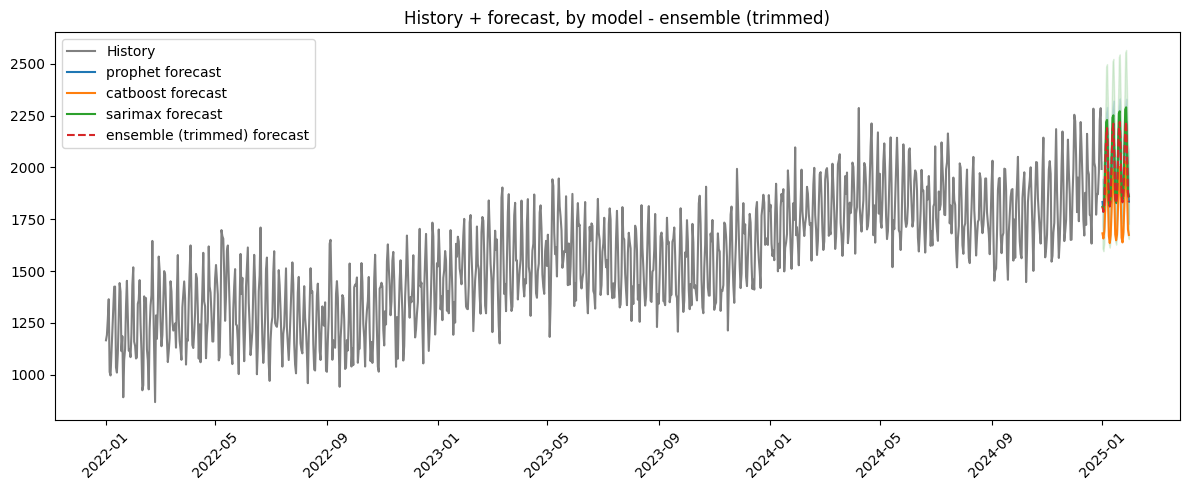

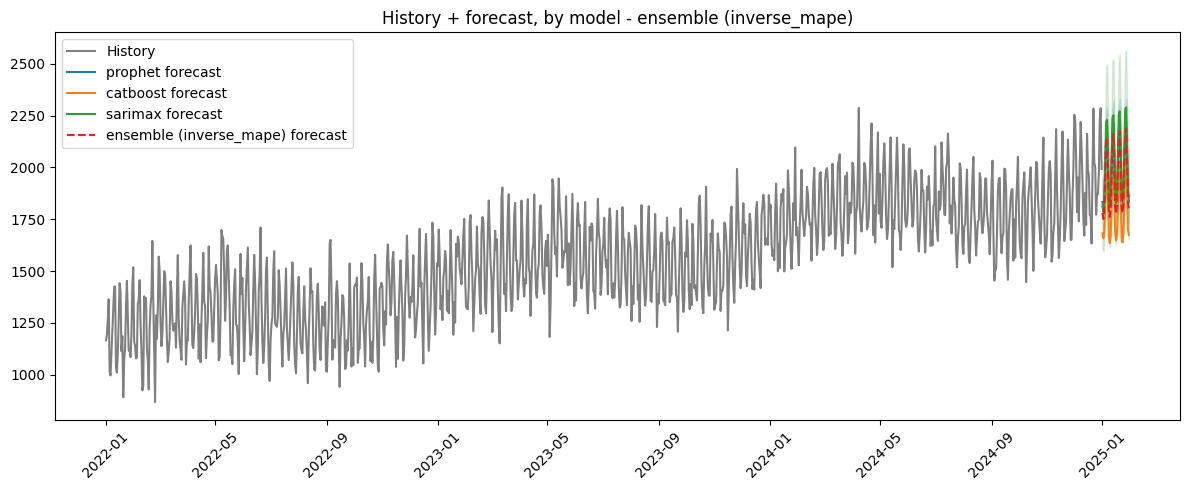

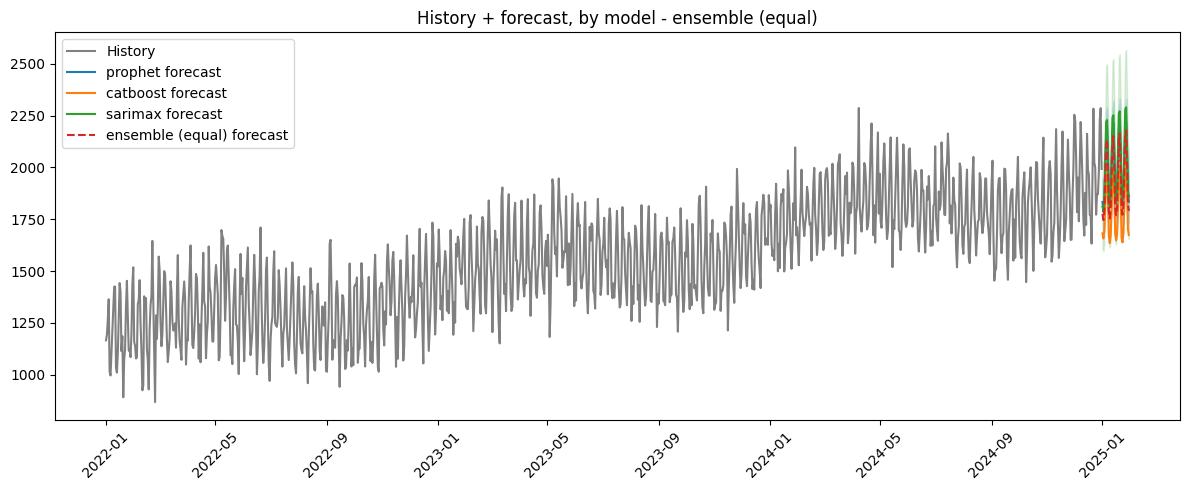

In [17]:
forecast_axes = plot_forecast(
    forecasts,
    history=df,
    date_column='date',
    target_column=TARGET,
    ensemble=forecaster.forecast_ensemble,
)
print('charts returned:', list(forecast_axes))
plt.show()

The forecast ensembles carry no MAPE of their own — there are no future actuals to score against.
Their screening and weighting reuse the **validation** MAPE from hyperparameter selection, which
`forecast()` has to perform anyway in order to know which parameters to fit with.

## 6. Export

One call writes the CSVs and the charts into a single folder.

In [18]:
from horizon_forecaster import DEFAULT_ENSEMBLE_METHOD

default_eval = (forecaster.evaluate_ensemble or {}).get(DEFAULT_ENSEMBLE_METHOD)

paths = export_forecast(
    forecasts,
    forecaster.forecast_ensemble,
    per_model_mape={m: r.mape.value for m, r in results.items()},
    per_model_validation_mape={m: r.validation_mape.value for m, r in results.items()},
    ensemble_mape=(
        default_eval.mape.value
        if default_eval is not None and default_eval.mape is not None
        else None
    ),
    mape_threshold=forecaster.mape_threshold,
    history=df,
    date_column='date',
    target_column=TARGET,
    output_dir='output',
    prefix='daily',
    save_plots=True,
)

for key in sorted(paths):
    print(f'{key:34s} {paths[key]}')

final_best_model                   output/daily_final_best_model.csv
final_ensemble_equal               output/daily_final_ensemble_equal.csv
final_ensemble_inverse_mape        output/daily_final_ensemble_inverse_mape.csv
final_ensemble_trimmed             output/daily_final_ensemble_trimmed.csv
model_summary                      output/daily_model_summary.csv
per_model                          output/daily_per_model.csv
plot_catboost                      output/daily_catboost.png
plot_ensemble_equal                output/daily_ensemble_equal.png
plot_ensemble_inverse_mape         output/daily_ensemble_inverse_mape.png
plot_ensemble_trimmed              output/daily_ensemble_trimmed.png
plot_overlay_equal                 output/daily_overlay_equal.png
plot_overlay_inverse_mape          output/daily_overlay_inverse_mape.png
plot_overlay_trimmed               output/daily_overlay_trimmed.png
plot_prophet                       output/daily_prophet.png
plot_sarimax                       ou

`final_ensemble_<method>` is written once per combination rule, and `final_best_model` alongside it.
The export deliberately does not choose between them — `model_summary.csv` carries the validation and
test MAPE side by side so you can make that call per run, with the evidence in hand.

In [19]:
pd.read_csv(paths['model_summary'])

,model,validation_mape,mape,ensemble_method,rule_applied,ensemble_weight,status
0,prophet,3.733859,4.074726,trimmed,trimmed,NaN,in_ensemble
1,catboost,4.486260,4.327124,trimmed,trimmed,NaN,in_ensemble
2,sarimax,3.745674,4.021650,trimmed,trimmed,NaN,in_ensemble
3,ensemble,NaN,NaN,trimmed,trimmed,1.000000,ensemble
4,prophet,3.733859,4.074726,inverse_mape,inverse_mape,0.353465,in_ensemble
5,catboost,4.486260,4.327124,inverse_mape,inverse_mape,0.294185,in_ensemble
6,sarimax,3.745674,4.021650,inverse_mape,inverse_mape,0.352350,in_ensemble
7,ensemble,NaN,NaN,inverse_mape,inverse_mape,1.000000,ensemble
8,prophet,3.733859,4.074726,equal,equal,0.333333,in_ensemble
9,catboost,4.486260,4.327124,equal,equal,0.333333,in_ensemble


## Where to go next

- [`docs/quickstart.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/quickstart.md) — the full API walkthrough
- [`docs/supported_models.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/supported_models.md) — what each model does, and its caveats
- [`docs/ensemble_methods.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/ensemble_methods.md) — the combination rules in detail
- [`docs/future_exog.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/future_exog.md) — the other future-driver strategies
- [`docs/design_notes.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/design_notes.md) — why the library is built this way

**Two honest caveats about this example.**

Every score here comes from a single test window, so it reflects one stretch of history rather than an
average over several origins — rolling-origin backtesting is a known gap, listed in the changelog.
And the data is simulated, with an only continuous driver that carries little signal, so treat the numbers as a demonstration
that the machinery works, not as evidence about how well these models forecast your series.